# Network Intrusion Detection System using AutoML on CICIDS2017 Dataset
**Dataset:** Friday-WorkingHours-Afternoon-PortScan  
Ishrath Basheer | P2836139

## Step 1: Install Dependencies
Installing all required libraries for this project.
If already installed, pip will confirm with *"Requirement already satisfied"*.

| Library | Purpose |
|---|---|
| `pandas`, `numpy` | Data processing |
| `scikit-learn` | ML models & metrics |
| `matplotlib`, `seaborn` | Visualisation |
| `shap` | Model explainability |
| `h2o` | H2O AutoML |
| `imbalanced-learn` | Imbalanced dataset tools |
| `tpot` | TPOT AutoML |

In [1]:
# ── Install Dependencies ──────────────────────────────────────────────

print("=" * 55)
print("  INSTALLING DEPENDENCIES")
print("=" * 55)
print("  Installing: pandas, numpy, scikit-learn,")
print("              matplotlib, seaborn, shap,")
print("              h2o, imbalanced-learn, tpot")
print("-" * 55)

!pip install pandas numpy scikit-learn matplotlib seaborn shap h2o imbalanced-learn tpot

print("=" * 55)
print("  Dependencies installed ")
print("=" * 55)

  INSTALLING DEPENDENCIES
  Installing: pandas, numpy, scikit-learn,
              matplotlib, seaborn, shap,
              h2o, imbalanced-learn, tpot
-------------------------------------------------------
  Dependencies installed 



[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Step 2: Environment & Library Versions
The following versions were used in this project. All results are reproducible using these exact versions with `random_state=42`.

In [2]:
import sys, platform
import pandas as pd
import numpy as np
import sklearn
import h2o
import shap
import matplotlib
import seaborn
import notebook

print("=" * 45)
print("  ENVIRONMENT & LIBRARY VERSIONS")
print("=" * 45)
print(f"Python        : {sys.version.split()[0]}")
print(f"Platform      : {platform.platform()}")
print(f"pandas        : {pd.__version__}")
print(f"numpy         : {np.__version__}")
print(f"scikit-learn  : {sklearn.__version__}")
print(f"h2o           : {h2o.__version__}")
print(f"shap          : {shap.__version__}")
print(f"matplotlib    : {matplotlib.__version__}")
print(f"seaborn       : {seaborn.__version__}")
print(f"notebook      : {notebook.__version__}")
print("=" * 45)

c:\Users\ishra\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  ENVIRONMENT & LIBRARY VERSIONS
Python        : 3.11.9
Platform      : Windows-10-10.0.26200-SP0
pandas        : 3.0.2
numpy         : 2.4.4
scikit-learn  : 1.5.2
h2o           : 3.46.0.10
shap          : 0.51.0
matplotlib    : 3.10.9
seaborn       : 0.13.2
notebook      : 7.5.6


## Step 3: Import Libraries
Importing all required libraries for data processing, visualisation,machine learning, AutoML, and model explainability.

| Category | Libraries |
|---|---|
| Data | `pandas`, `numpy` |
| Visualisation | `matplotlib`, `seaborn` |
| Machine Learning | `scikit-learn` |
| AutoML | `TPOT`, `H2O AutoML` |
| Explainability | `SHAP` |

In [3]:
# ── Library Imports ───────────────────────────────────────────────────

print("=" * 55)
print("  IMPORTING LIBRARIES")
print("=" * 55)

# Standard libraries
import os
import warnings
warnings.filterwarnings('ignore')

# Data processing
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn — preprocessing, models, and metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, ConfusionMatrixDisplay)

# AutoML - TPOT (genetic programming) and H2O AutoML
from tpot import TPOTClassifier
import h2o
from h2o.automl import H2OAutoML

# Explainability - SHAP for feature importance
import shap

print("-" * 55)
print("  Category        Library         ")
print("-" * 55)
print("  Data          : pandas, numpy")
print("  Visualisation : matplotlib, seaborn")
print("  ML Models     : scikit-learn")
print("  AutoML        : TPOT, H2O AutoML")
print("  Explainability: SHAP")
print("-" * 55)
print("  Libraries have been imported successfully")
print("=" * 55)

  IMPORTING LIBRARIES
-------------------------------------------------------
  Category        Library         
-------------------------------------------------------
  Data          : pandas, numpy
  Visualisation : matplotlib, seaborn
  ML Models     : scikit-learn
  AutoML        : TPOT, H2O AutoML
  Explainability: SHAP
-------------------------------------------------------
  Libraries have been imported successfully


## Step 4: Load Dataset
Loading the CICIDS2017 dataset: **Friday-WorkingHours-Afternoon-PortScan**.
This dataset contains network flow records labelled as **BENIGN** or **PortScan**.
> CICIDS2017 is known to have leading spaces in column names - stripped automatically below.

In [4]:
# ── Load Dataset ──────────────────────────────────────────────────────

print("=" * 60)
print("  LOADING DATASET")
print("=" * 60)

file_path = "data/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv"

print(f"  File : {file_path}")
print("-" * 60)

# Load CSV - low_memory=False prevents mixed-type column warnings
df = pd.read_csv(file_path, low_memory=False)

# Fix column name spacing  known issue with CICIDS2017 dataset
# Some columns have leading/trailing spaces e.g. ' Label' instead of 'Label'
df.columns = df.columns.str.strip()

# ── Quick Summary ─────────────────────────────────────────────
print(f"  {'Shape':<20} : {df.shape[0]:,} rows × {df.shape[1]} columns")
print("-" * 60)
print("  Label Distribution:")
label_counts = df['Label'].value_counts() if 'Label' in df.columns else df[' Label'].value_counts()
for label, count in label_counts.items():
    pct = count / len(df) * 100
    print(f"    {label:<15} : {count:>7,}  ({pct:.1f}%)")
print("-" * 60)
print("  Dataset has been loaded")
print("=" * 60)

# Preview first 5 rows
df.head()

  LOADING DATASET
  File : data/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
------------------------------------------------------------
  Shape                : 286,467 rows × 79 columns
------------------------------------------------------------
  Label Distribution:
    PortScan        : 158,930  (55.5%)
    BENIGN          : 127,537  (44.5%)
------------------------------------------------------------
  Dataset has been loaded


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,22,1266342,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,22,1319353,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,22,160,1,1,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,22,1303488,41,42,2728,6634,456,0,66.536585,110.129945,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,35396,77,1,2,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


## Step 5: Exploratory Data Analysis (EDA)
A quick statistical overview of the raw dataset before any preprocessing.
Covers dataset shape, class distribution, missing values, and feature data types.

In [5]:
# ── Basic EDA ─────────────────────────────────────────────────────────

print("=" * 55)
print("  EXPLORATORY DATA ANALYSIS (EDA)")
print("=" * 55)

# Dataset dimensions
print(f"  {'Dataset Shape':<25}: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("-" * 55)

# Class distribution - checks for imbalance
print("  Label Distribution:")
for label, count in df['Label'].value_counts().items():
    pct = count / len(df) * 100
    print(f"    {label:<15} : {count:>7,}  ({pct:.1f}%)")
print("-" * 55)

# Missing values - important to catch before modelling
missing = df.isnull().sum().sum()
print(f"  {'Missing Values':<25}: {missing}")
print(f"  {'Missing (%)':<25}: {round(missing / df.size * 100, 4)}%")
print("-" * 55)

# Feature data types breakdown
print("  Data Types:")
for dtype, count in df.dtypes.value_counts().items():
    print(f"    {str(dtype):<15} : {count} columns")
print("-" * 55)

# Total features
print(f"  {'Total Features':<25}: {len(df.columns)}")
print(f"  {'Feature columns':<25}: {len(df.columns) - 1}  (+1 label column)")
print("=" * 55)

  EXPLORATORY DATA ANALYSIS (EDA)
  Dataset Shape            : 286,467 rows × 79 columns
-------------------------------------------------------
  Label Distribution:
    PortScan        : 158,930  (55.5%)
    BENIGN          : 127,537  (44.5%)
-------------------------------------------------------
  Missing Values           : 15
  Missing (%)              : 0.0001%
-------------------------------------------------------
  Data Types:
    int64           : 54 columns
    float64         : 24 columns
    str             : 1 columns
-------------------------------------------------------
  Total Features           : 79
  Feature columns          : 78  (+1 label column)


## Step 6: Data Preprocessing
Preparing the dataset for model training through the following steps:
1. **Label fix** - strip whitespace from column name
2. **Clean** - replace infinite values and drop null rows
3. **Encode** - convert BENIGN/PortScan labels to 0/1 using LabelEncoder
4. **Split** - 80/20 stratified train/test split
5. **Scale** - StandardScaler fitted on train set only (prevents data leakage)

In [6]:
# ── Preprocessing ─────────────────────────────────────────────────────

print("=" * 55)
print("  DATA PREPROCESSING")
print("=" * 55)

# ── Step 1: Fix label column name ─────────────────────────────
# CICIDS2017 dataset sometimes has a leading space in 'Label' column
label_col = 'Label' if 'Label' in df.columns else ' Label'
df.rename(columns={label_col: 'Label'}, inplace=True)

# ── Step 2: Clean - remove infinities and nulls ───────────────
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

print(f"  {'Shape after cleaning':<25}: {df.shape}")
print(f"  {'Rows removed':<25}: {286467 - df.shape[0]}")
print("-" * 55)
print("  Label Distribution:")
print(df['Label'].value_counts().to_string())
print("-" * 55)

# ── Step 3: Encode labels - BENIGN=0, PortScan=1 ─────────────
le = LabelEncoder()
df['Label_encoded'] = le.fit_transform(df['Label'])

print(f"  {'Label classes':<25}: {list(le.classes_)}")
print(f"  {'Encoding':<25}: BENIGN=0 | PortScan=1")
print("-" * 55)

# ── Step 4: Features and target ───────────────────────────────
X = df.drop(['Label', 'Label_encoded'], axis=1)
y = df['Label_encoded']

# Stratified 80/20 split - preserves class ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"  {'Train size':<25}: {X_train.shape}")
print(f"  {'Test size':<25}: {X_test.shape}")
print("-" * 55)

# ── Step 5: Scale features ────────────────────────────────────
# Fit scaler ONLY on train set to prevent data leakage into test set
scaler         = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f"  {'Scaler':<25}: StandardScaler")
print(f"  {'Fit on':<25}: Train set only (no leakage)")
print("-" * 55)
print("  Preprocessing is complete")
print("=" * 55)

  DATA PREPROCESSING
  Shape after cleaning     : (286096, 79)
  Rows removed             : 371
-------------------------------------------------------
  Label Distribution:
Label
PortScan    158804
BENIGN      127292
-------------------------------------------------------
  Label classes            : ['BENIGN', 'PortScan']
  Encoding                 : BENIGN=0 | PortScan=1
-------------------------------------------------------
  Train size               : (228876, 78)
  Test size                : (57220, 78)
-------------------------------------------------------
  Scaler                   : StandardScaler
  Fit on                   : Train set only (no leakage)
-------------------------------------------------------
  Preprocessing is complete


## Step 7: Baseline Model - Logistic Regression
Training a Logistic Regression model as the baseline classifier.
Uses scaled features with a maximum of 1000 iterations.
Evaluated using Classification Report, ROC-AUC, and Confusion Matrix.

  LOGISTIC REGRESSION - BASELINE MODEL
  Config : max_iter=1000 | random_state=42
------------------------------------------------------------
  Training Time : 4.11s
------------------------------------------------------------
  Classification Report:
------------------------------------------------------------
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     25459
    PortScan       1.00      1.00      1.00     31761

    accuracy                           1.00     57220
   macro avg       1.00      1.00      1.00     57220
weighted avg       1.00      1.00      1.00     57220

------------------------------------------------------------
  ROC-AUC       : 0.9999

  CONFUSION MATRIX - Logistic Regression


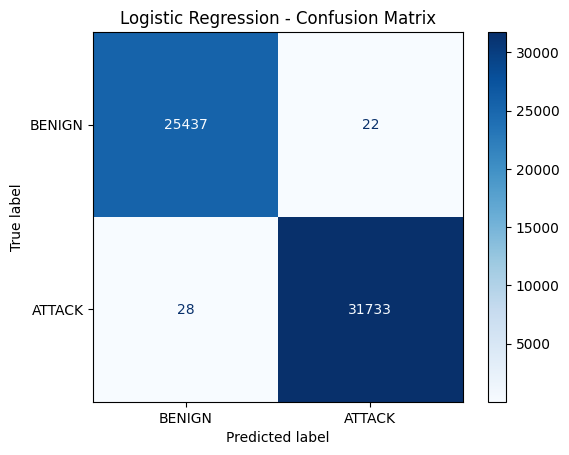

------------------------------------------------------------
 Confusion matrix saved as confusion_matrix_lr.png


In [7]:
# ── Logistic Regression ───────────────────────────────────────────────

print("=" * 60)
print("  LOGISTIC REGRESSION - BASELINE MODEL")
print("=" * 60)
print("  Config : max_iter=1000 | random_state=42")
print("-" * 60)

import time

# Train Logistic Regression on scaled features (scaling is required for LR)
start    = time.time()
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
lr_train_time = round(time.time() - start, 2)

# ── Predictions ───────────────────────────────────────────────
# Generate class predictions and ATTACK probabilities on test set
y_pred_lr = lr_model.predict(X_test_scaled)
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

# ── Metrics ───────────────────────────────────────────────────
print(f"  Training Time : {lr_train_time}s")
print("-" * 60)
print("  Classification Report:")
print("-" * 60)
print(classification_report(y_test, y_pred_lr, target_names=le.classes_))
print("-" * 60)
print(f"  ROC-AUC       : {roc_auc_score(y_test, y_prob_lr):.4f}")
print("=" * 60)

# ── Confusion Matrix ──────────────────────────────────────────
print()
print("=" * 60)
print("  CONFUSION MATRIX - Logistic Regression")
print("=" * 60)

cm_lr = confusion_matrix(y_test, y_pred_lr)
disp  = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=['BENIGN', 'ATTACK'])
disp.plot(cmap='Blues')
plt.title("Logistic Regression - Confusion Matrix")
plt.savefig("confusion_matrix_lr.png", dpi=150, bbox_inches='tight')
plt.show()

print("-" * 60)
print(" Confusion matrix saved as confusion_matrix_lr.png")
print("=" * 60)




## Step 8: Random Forest Classifier
Training a Random Forest with 100 estimators on the preprocessed dataset.
Evaluated using Classification Report, ROC-AUC, and Confusion Matrix.
Feature Importance plot highlights the top 15 most influential features.

  RANDOM FOREST CLASSIFIER
  Config : n_estimators=100 | random_state=42 | n_jobs=-1
------------------------------------------------------------
  Training Time : 22.2s
------------------------------------------------------------
  Classification Report:
------------------------------------------------------------
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     25459
    PortScan       1.00      1.00      1.00     31761

    accuracy                           1.00     57220
   macro avg       1.00      1.00      1.00     57220
weighted avg       1.00      1.00      1.00     57220

------------------------------------------------------------
  ROC-AUC       : 1.0000

  CONFUSION MATRIX - Random Forest


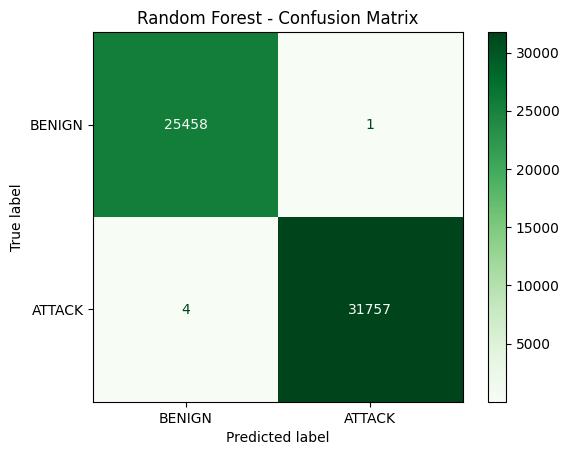

------------------------------------------------------------
 Confusion matrix saved as confusion_matrix_rf.png

  FEATURE IMPORTANCE - Top 15 Features
  Top 5 preview:
------------------------------------------------------------
  1. Fwd Packet Length Mean                   0.066291
  2. Flow IAT Max                             0.066284
  3. Bwd Packets/s                            0.065682
  4. Average Packet Size                      0.064058
  5. Subflow Fwd Bytes                        0.063421
------------------------------------------------------------


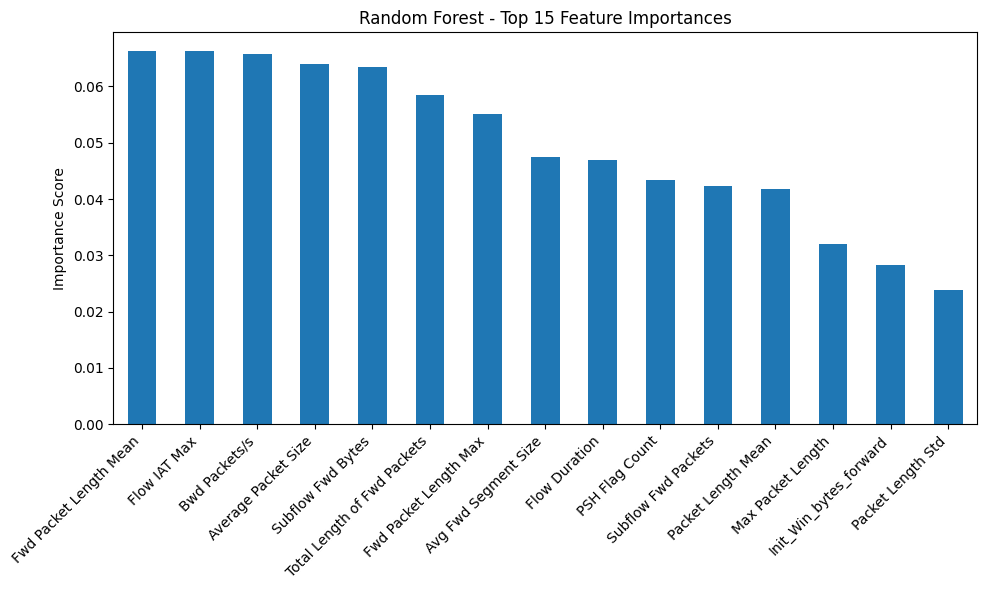

------------------------------------------------------------
 Feature importance plot saved as rf_feature_importance.png


In [8]:
# ── Random Forest ─────────────────────────────────────────────────────

print("=" * 60)
print("  RANDOM FOREST CLASSIFIER")
print("=" * 60)
print("  Config : n_estimators=100 | random_state=42 | n_jobs=-1")
print("-" * 60)

import time

# Train Random Forest on unscaled data (tree models don't need scaling)
start    = time.time()
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_train_time = round(time.time() - start, 1)

# ── Predictions ───────────────────────────────────────────────
# Generate class predictions and ATTACK probabilities on test set
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# ── Metrics ───────────────────────────────────────────────────
print(f"  Training Time : {rf_train_time}s")
print("-" * 60)
print("  Classification Report:")
print("-" * 60)
print(classification_report(y_test, y_pred_rf, target_names=le.classes_))  
print("-" * 60)
print(f"  ROC-AUC       : {roc_auc_score(y_test, y_prob_rf):.4f}")
print("=" * 60)

# ── Confusion Matrix ──────────────────────────────────────────
print()
print("=" * 60)
print("  CONFUSION MATRIX - Random Forest")
print("=" * 60)

cm_rf = confusion_matrix(y_test, y_pred_rf)
disp  = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['BENIGN', 'ATTACK'])
disp.plot(cmap='Greens')
plt.title("Random Forest - Confusion Matrix")
plt.savefig("confusion_matrix_rf.png", dpi=150, bbox_inches='tight')
plt.show()

print("-" * 60)
print(" Confusion matrix saved as confusion_matrix_rf.png")
print("=" * 60)

# ── Feature Importance Plot ───────────────────────────────────
print()
print("=" * 60)
print("  FEATURE IMPORTANCE - Top 15 Features")
print("=" * 60)

# Extract and rank feature importances from trained model
importances = rf_model.feature_importances_
feat_imp    = pd.Series(importances, index=X_train.columns) \
                .sort_values(ascending=False).head(15)

print("  Top 5 preview:")
print("-" * 60)
for rank, (feat, score) in enumerate(feat_imp.head(5).items(), start=1):
    print(f"  {rank}. {feat:<40} {score:.6f}")
print("-" * 60)

plt.figure(figsize=(10, 6))
feat_imp.plot(kind='bar')
plt.title("Random Forest - Top 15 Feature Importances")
plt.ylabel("Importance Score")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("rf_feature_importance.png", dpi=150, bbox_inches='tight')
plt.show()

print("-" * 60)
print(" Feature importance plot saved as rf_feature_importance.png")
print("=" * 60)

## Step 9: Save Random Forest Model
Saving the trained Random Forest model as a `.pkl` file using pickle.
This model is later loaded by the Streamlit application for live predictions.

In [9]:
# ── Save Random Forest Model ──────────────────────────────────────────

print("=" * 55)
print("  SAVING RANDOM FOREST MODEL")
print("=" * 55)

import pickle
import os

# Save model to the current project directory 
save_path = "rf_model.pkl"

with open(save_path, "wb") as f:
    pickle.dump(rf_model, f)

print(f"  Model     : RandomForestClassifier")
print(f"  Saved to  : {save_path}")
print("-" * 55)
print("  To reload this model later:")
print('  with open("rf_model.pkl", "rb") as f:')
print('  model = pickle.load(f)')
print("-" * 55)
print(" RF model saved")
print("=" * 55)

  SAVING RANDOM FOREST MODEL
  Model     : RandomForestClassifier
  Saved to  : rf_model.pkl
-------------------------------------------------------
  To reload this model later:
  with open("rf_model.pkl", "rb") as f:
  model = pickle.load(f)
-------------------------------------------------------
 RF model saved


## TPOT AutoML (Exploratory - Not included in report)
This section was run as an exploratory experiment.TPOT was excluded from the final comparison due to convergence instability and significantly longer runtime.
H2O AutoML is the primary AutoML model evaluated in this project.

  AutoML - TPOT (Genetic Programming)
  Config : max_time=10mins | cv=3 | random_state=42
------------------------------------------------------------


Version 0.12.2 of tpot is outdated. Version 1.1.0 was released Thursday July 03, 2025.


                                                                               
16.04 minutes have elapsed. TPOT will close down.                              
TPOT closed during evaluation in one generation.
                                                                               
                                                                               
TPOT closed prematurely. Will use the current best pipeline.
                                                                               
Best pipeline: RandomForestClassifier(MinMaxScaler(input_matrix), bootstrap=True, criterion=gini, max_features=0.2, min_samples_leaf=8, min_samples_split=4, n_estimators=100)

  AutoML (TPOT) - RESULTS
  Training Time  : 1084.82s
  Best Pipeline  : RandomForestClassifier
------------------------------------------------------------
  Classification Report:
------------------------------------------------------------
              precision    recall  f1-score   support

      BENIGN    

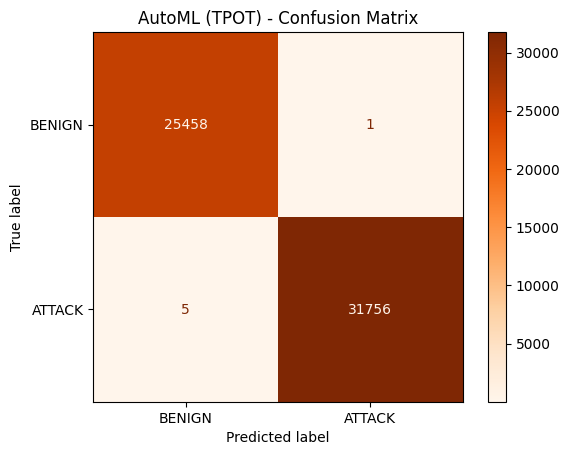

------------------------------------------------------------
  Confusion matrix saved as confusion_matrix_tpot.png


In [10]:
# ── AutoML: TPOT ──────────────────────────────────────────────────────

print("=" * 60)
print("  AutoML - TPOT (Genetic Programming)")
print("=" * 60)
print("  Config : max_time=10mins | cv=3 | random_state=42")
print("-" * 60)

import time

# Train TPOT - searches for the best pipeline using genetic programming
start = time.time()
tpot  = TPOTClassifier(
    max_time_mins=10,
    random_state=42,
    cv=3,
    n_jobs=1,
    verbosity=2
)
tpot.fit(X_train_scaled, y_train)
tpot_train_time = round(time.time() - start, 2)

# ── Predictions ───────────────────────────────────────────────
# Generate class predictions and probabilities on test set
y_pred_tpot = tpot.predict(X_test_scaled)
y_prob_tpot = tpot.predict_proba(X_test_scaled)[:, 1]

# ── Metrics ───────────────────────────────────────────────────
print()
print("=" * 60)
print("  AutoML (TPOT) - RESULTS")
print("=" * 60)
print(f"  Training Time  : {tpot_train_time}s")
print(f"  Best Pipeline  : {tpot.fitted_pipeline_.steps[-1][1].__class__.__name__}")
print("-" * 60)
print("  Classification Report:")
print("-" * 60)
print(classification_report(y_test, y_pred_tpot, target_names=le.classes_))
print("-" * 60)
print(f"  ROC-AUC        : {roc_auc_score(y_test, y_prob_tpot):.4f}")
print("=" * 60)

# ── Confusion Matrix ──────────────────────────────────────────
print()
print("=" * 60)
print("  CONFUSION MATRIX - TPOT AutoML")
print("=" * 60)

cm_tpot = confusion_matrix(y_test, y_pred_tpot)
disp    = ConfusionMatrixDisplay(confusion_matrix=cm_tpot, display_labels=['BENIGN', 'ATTACK'])
disp.plot(cmap='Oranges')
plt.title("AutoML (TPOT) - Confusion Matrix")
plt.savefig("confusion_matrix_tpot.png", dpi=150, bbox_inches='tight')
plt.show()

print("-" * 60)
print("  Confusion matrix saved as confusion_matrix_tpot.png")
print("=" * 60)

## Step 11: AutoML - H2O AutoML (GBM)
H2O AutoML automatically trains and tunes multiple models within a 600-second time budget, evaluating up to 20 models. The best model is selected by AUC score.
Training is performed on the scaled train set and evaluated on the held-out test set.

  AutoML - H2O INITIALISATION
Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
; OpenJDK 64-Bit Server VM Temurin-25.0.3+9 (build 25.0.3+9-LTS, mixed mode, sharing)
  Starting server from C:\Users\ishra\AppData\Local\Programs\Python\Python311\Lib\site-packages\h2o\backend\bin\h2o.jar
  Ice root: C:\Users\ishra\AppData\Local\Temp\tmp5d332k73
  JVM stdout: C:\Users\ishra\AppData\Local\Temp\tmp5d332k73\h2o_ishra_started_from_python.out
  JVM stderr: C:\Users\ishra\AppData\Local\Temp\tmp5d332k73\h2o_ishra_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.


H2O_cluster_uptime:,05 secs
H2O_cluster_timezone:,Asia/Dubai
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.10
H2O_cluster_version_age:,2 months and 26 days
H2O_cluster_name:,H2O_from_python_ishra_71hfe8
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,930 Mb
H2O_cluster_total_cores:,0
H2O_cluster_allowed_cores:,0
H2O_cluster_status:,"locked, healthy"


------------------------------------------------------------
  Converting train/test sets to H2OFrame...
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
  Train H2OFrame : (228876, 79)
  Test H2OFrame  : (57220, 79)
------------------------------------------------------------
  Training H2O AutoML...
  Config : max_runtime=600s | max_models=20 | seed=42
------------------------------------------------------------
AutoML progress: |
13:31:45.843: AutoML: XGBoost is not available; skipping it.
13:31:46.29: _train param, Dropping bad and constant columns: [Bwd Avg Packets/Bulk, Fwd URG Flags, Fwd Avg Bulk Rate, Bwd PSH Flags, Bwd URG Flags, CWE Flag Count, Bwd Avg Bytes/Bulk, Fwd Avg Bytes/Bulk, Fwd Avg Packets/Bulk, Bwd Avg Bulk Rate]

██████████████████
13:34:28.670: _train param, Dropping bad and constant columns: [Bwd Avg Packets/Bulk, Fwd URG F

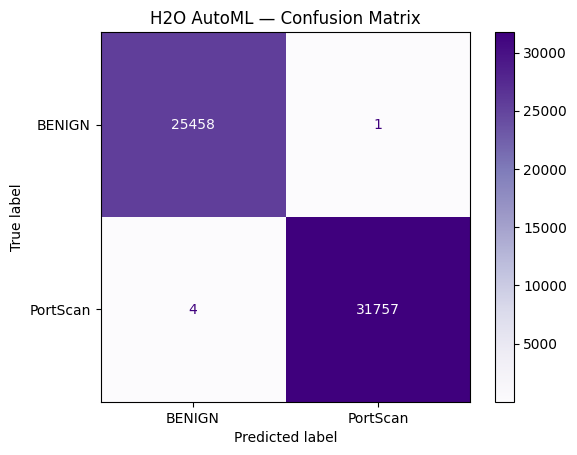

------------------------------------------------------------
 Confusion matrix is saved as confusion_matrix_h2o.png


In [11]:
# ── AutoML: H2O ───────────────────────────────────────────────────────

print("=" * 60)
print("  AutoML - H2O INITIALISATION")
print("=" * 60)

# Start H2O cluster
h2o.init()

print("-" * 60)

# ── Convert to H2OFrame ───────────────────────────────────────
print("  Converting train/test sets to H2OFrame...")
train_h2o = h2o.H2OFrame(pd.concat([X_train, y_train.rename('Label')], axis=1))
test_h2o  = h2o.H2OFrame(pd.concat([X_test,  y_test.rename('Label')],  axis=1))

# Cast label column as factor (required for classification in H2O)
train_h2o['Label'] = train_h2o['Label'].asfactor()
test_h2o['Label']  = test_h2o['Label'].asfactor()

print(f"  Train H2OFrame : {train_h2o.shape}")
print(f"  Test H2OFrame  : {test_h2o.shape}")
print("-" * 60)

# ── Train H2O AutoML ──────────────────────────────────────────
print("  Training H2O AutoML...")
print("  Config : max_runtime=600s | max_models=20 | seed=42")
print("-" * 60)

start    = time.time()
aml      = H2OAutoML(max_runtime_secs=600, max_models=20, seed=42)
features = X_train.columns.tolist()
aml.train(x=features, y='Label', training_frame=train_h2o)
h2o_train_time = round(time.time() - start, 2)

# ── Evaluate Best Model ───────────────────────────────────────
perf = aml.leader.model_performance(test_h2o)

print("=" * 60)
print("  H2O AutoML - RESULTS")
print("=" * 60)
print(f"  Training Time : {h2o_train_time}s")
print(f"  Best Model    : {aml.leader.model_id}")
print(f"  ROC-AUC       : {perf.auc():.4f}")
print("-" * 60)
print("  Leaderboard (Top 5):")
print(aml.leaderboard.head())
print("=" * 60)

# ── Confusion Matrix ──────────────────────────────────────────
print()
print("=" * 60)
print("  CONFUSION MATRIX - H2O AutoML")
print("=" * 60)

# Get predictions from best model
h2o_pred = aml.leader.predict(test_h2o).as_data_frame()['predict'].values
cm_h2o   = confusion_matrix(y_test, h2o_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_h2o, display_labels=le.classes_)
disp.plot(cmap='Purples')
plt.title("H2O AutoML — Confusion Matrix")
plt.savefig("confusion_matrix_h2o.png", dpi=150, bbox_inches='tight')
plt.show()

print("-" * 60)
print(" Confusion matrix is saved as confusion_matrix_h2o.png")
print("=" * 60)

## Step 12: Save H2O AutoML Best Model
Saving the best model from H2O AutoML to disk for future use.
The model can be reloaded later using `h2o.load_model(path)`.

In [12]:
# ── Save H2O Best Model ───────────────────────────────────────────────

print("=" * 60)
print("  SAVING H2O AutoML BEST MODEL")
print("=" * 60)

# Create models directory if it doesn't exist
os.makedirs("models", exist_ok=True)

# Save the best model to disk (force=True overwrites if already exists)
model_path = h2o.save_model(model=aml.leader, path="models", force=True)

print(f"  Model ID   : {aml.leader.model_id}")
print(f"  Saved to   : models/")
print(f"  Full path  : {model_path}")
print("-" * 60)
print("  To reload this model later:")
print('  loaded_model = h2o.load_model(path)')
print("-" * 60)
print("  Model has been saved successfully")
print("=" * 60)

  SAVING H2O AutoML BEST MODEL
  Model ID   : GBM_grid_1_AutoML_1_20260607_133144_model_3
  Saved to   : models/
  Full path  : C:\Users\ishra\Downloads\Project\models\GBM_grid_1_AutoML_1_20260607_133144_model_3
------------------------------------------------------------
  To reload this model later:
  loaded_model = h2o.load_model(path)
------------------------------------------------------------
  Model has been saved successfully


## Step 13: H2O AutoML - Best Model Details & Performance
Detailed evaluation of the best model selected by H2O AutoML on the held-out test set.
Metrics include AUC, F1, Precision, Recall, and Logloss.
The confusion matrix shows exact misclassification counts at the optimal F1 threshold.

In [13]:
# ── Best Model Details & Metrics ──────────────────────────────────────

best_model = aml.leader
perf       = best_model.model_performance(test_h2o)

print("=" * 60)
print("  H2O AutoML - BEST MODEL DETAILS")
print("=" * 60)
print(f"  Model ID   : {best_model.model_id}")
print(f"  Model Type : {type(best_model).__name__}")
print("-" * 60)

# ── Performance Metrics ───────────────────────────────────────
print("  PERFORMANCE METRICS")
print("-" * 60)
print(f"  {'AUC':<12} : {round(perf.auc(), 4)}")
print(f"  {'Max F1':<12} : {round(perf.F1()[0][1], 4)}")
print(f"  {'Precision':<12} : {round(perf.precision()[0][1], 4)}")
print(f"  {'Recall':<12} : {round(perf.recall()[0][1], 4)}")
print(f"  {'Logloss':<12} : {round(perf.logloss(), 4)}")
print("-" * 60)

# ── Confusion Matrix ──────────────────────────────────────────
print("  CONFUSION MATRIX  (Act / Pred)")
print("  Classes : 0 = BENIGN  |  1 = ATTACK")
print("-" * 60)
print(perf.confusion_matrix())
print("-" * 60)

# ── Misclassification summary using to_list() ────────────
# .to_list() returns [[TN, FP], [FN, TP]]
cm_list    = perf.confusion_matrix().to_list()

tn = cm_list[0][0]   # True Negatives  (Benign predicted as Benign)
fp = cm_list[0][1]   # False Positives (Benign predicted as Attack)
fn = cm_list[1][0]   # False Negatives (Attack predicted as Benign)
tp = cm_list[1][1]   # True Positives  (Attack predicted as Attack)

total      = tn + fp + fn + tp
misclassed = fp + fn

print(f"  Total Samples    : {total:,}")
print(f"  Misclassified    : {misclassed}  (FP={fp}, FN={fn})")
print(f"  Accuracy         : {round((total - misclassed) / total * 100, 4)}%")
print("=" * 60)

  H2O AutoML - BEST MODEL DETAILS
  Model ID   : GBM_grid_1_AutoML_1_20260607_133144_model_3
  Model Type : H2OGradientBoostingEstimator
------------------------------------------------------------
  PERFORMANCE METRICS
------------------------------------------------------------
  AUC          : 1.0
  Max F1       : 1.0
  Precision    : 1.0
  Recall       : 1.0
  Logloss      : 0.0006
------------------------------------------------------------
  CONFUSION MATRIX  (Act / Pred)
  Classes : 0 = BENIGN  |  1 = ATTACK
------------------------------------------------------------
Confusion Matrix (Act/Pred) for max f1 @ threshold = 0.000516807645876438
       0      1      Error    Rate
-----  -----  -----  -------  -------------
0      25457  2      0.0001   (2.0/25459.0)
1      1      31760  0        (1.0/31761.0)
Total  25458  31762  0.0001   (3.0/57220.0)
------------------------------------------------------------
  Total Samples    : 57,220
  Misclassified    : 3  (FP=2, FN=1)
  Accur

## Step 14: H2O AutoML Leaderboard - Top 20 Models
All models trained by H2O AutoML ranked by AUC score.
The best model (rank 1) is automatically selected as the leader and used for all subsequent predictions and evaluations.

In [14]:
# ── H2O AutoML Leaderboard ────────────────────────────────────────────

print("=" * 75)
print("  H2O AutoML LEADERBOARD - TOP MODELS")
print("=" * 75)
print(f"  Best Model : {aml.leader.model_id}")
print(f"  Total Models Trained : {aml.leaderboard.nrows}")
print("-" * 75)

# Display leaderboard ranked by AUC (higher is better)
print(aml.leaderboard.head(rows=20))

print("-" * 75)
print("  Metrics Guide:")
print("    AUC     - Area Under ROC Curve       (higher = better, max 1.0)")
print("    AUCPR   - Area Under Precision-Recall (higher = better, max 1.0)")
print("    Logloss - Logarithmic Loss            (lower  = better, min 0.0)")
print("    RMSE    - Root Mean Squared Error     (lower  = better)")
print("=" * 75)

  H2O AutoML LEADERBOARD - TOP MODELS
  Best Model : GBM_grid_1_AutoML_1_20260607_133144_model_3
  Total Models Trained : 14
---------------------------------------------------------------------------
model_id                                          auc      logloss     aucpr    mean_per_class_error        rmse          mse
GBM_grid_1_AutoML_1_20260607_133144_model_3  1         0.000441723  1                    4.88186e-05  0.0111298   0.000123872
GBM_3_AutoML_1_20260607_133144               1         0.000594105  1                    4.88186e-05  0.0132713   0.000176128
GBM_2_AutoML_1_20260607_133144               1         0.000502868  1                    4.88186e-05  0.0124246   0.000154371
GBM_4_AutoML_1_20260607_133144               1         0.000599538  1                    9.76372e-05  0.0124797   0.000155743
GBM_5_AutoML_1_20260607_133144               1         0.000511412  1                    4.88186e-05  0.0120028   0.000144066
GBM_1_AutoML_1_20260607_133144             

## Step 15: Sample Predictions - H2O AutoML Best Model
Running the best H2O AutoML model on the first 5 test samples to verify prediction output format. Shows raw class prediction, probabilities for
both classes, and the human-readable label (BENIGN / ATTACK).

In [15]:
# ── Sample Predictions ────────────────────────────────────────────────

print("=" * 60)
print("  SAMPLE PREDICTIONS - H2O AutoML Best Model")
print("=" * 60)
print(f"  Model   : {aml.leader.model_id}")
print(f"  Samples : First 5 rows of test set")
print("-" * 60)

# Predict on first 5 test samples only
sample      = test_h2o[:5]
predictions = aml.leader.predict(sample)

# Convert to pandas and add human-readable label
preds_df = predictions.as_data_frame()
preds_df['Prediction Label'] = preds_df['predict'].map({0: 'BENIGN', 1: 'ATTACK'})

# .head(5) to show only 5 rows 
print(preds_df[['predict', 'p0', 'p1', 'Prediction Label']].head(5).to_string(index=True))

print("-" * 60)
print("  Columns:")
print("    predict          - predicted class  (0 = BENIGN, 1 = ATTACK)")
print("    p0               - probability of BENIGN")
print("    p1               - probability of ATTACK")
print("    Prediction Label - human-readable label")
print("=" * 60)

  SAMPLE PREDICTIONS - H2O AutoML Best Model
  Model   : GBM_grid_1_AutoML_1_20260607_133144_model_3
  Samples : First 5 rows of test set
------------------------------------------------------------
gbm prediction progress: |███████████████████████████████████████████████████████| (done) 100%
   predict        p0        p1 Prediction Label
0        1  0.000007  0.999993           ATTACK
1        1  0.000169  0.999831           ATTACK
2        1  0.000007  0.999993           ATTACK
3        1  0.000007  0.999993           ATTACK
4        1  0.037130  0.962870           ATTACK
------------------------------------------------------------
  Columns:
    predict          - predicted class  (0 = BENIGN, 1 = ATTACK)
    p0               - probability of BENIGN
    p1               - probability of ATTACK
    Prediction Label - human-readable label


## Step 16: SHAP Explainability - Random Forest
SHAP (SHapley Additive exPlanations) explains individual feature contributions to each prediction. A 500-sample subset is used for efficiency.
The beeswarm plot shows both the magnitude and direction of each feature's impact on the model output (BENIGN vs ATTACK).

  SHAP EXPLAINABILITY - RANDOM FOREST
  Sample size : 500 rows
  Features    : 78
------------------------------------------------------------
  Computing SHAP values...
  SHAP values shape : (500, 78, 2)
------------------------------------------------------------


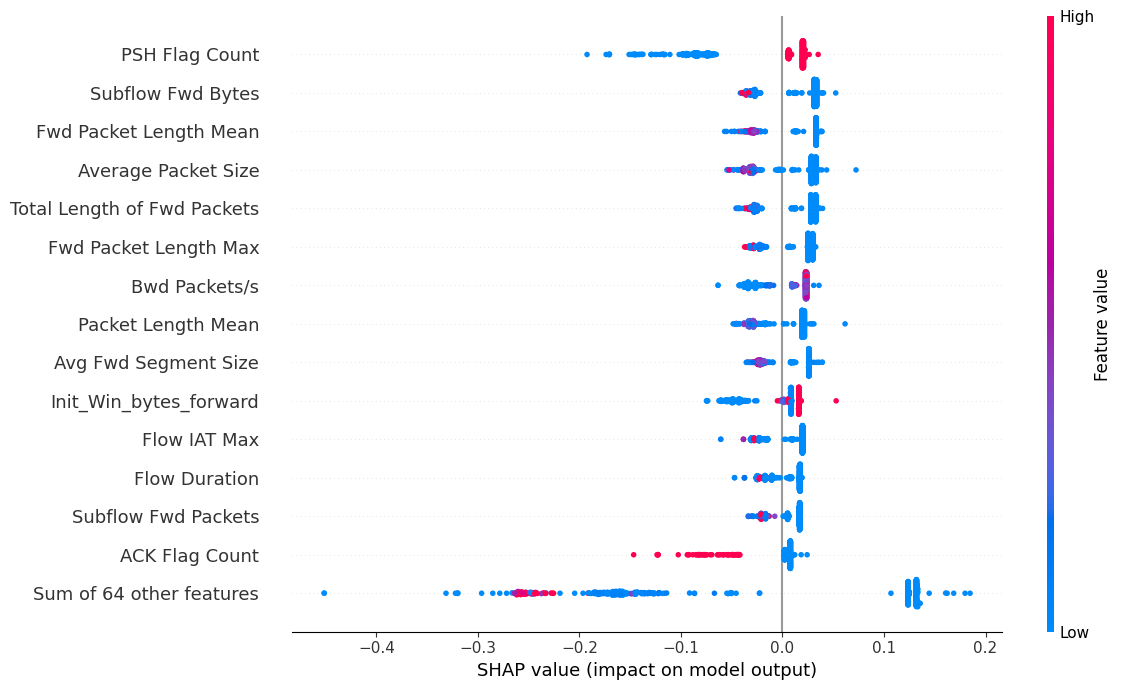

------------------------------------------------------------
 Beeswarm plot saved as shap_summary.png


In [16]:
# ── SHAP Explainability (Random Forest) ───────────────────────────────

print("=" * 60)
print("  SHAP EXPLAINABILITY - RANDOM FOREST")
print("=" * 60)

# Sample 500 rows from test set for SHAP computation (faster than full test set)
sample = X_test.sample(500, random_state=42).reset_index(drop=True)
print(f"  Sample size : {len(sample)} rows")
print(f"  Features    : {sample.shape[1]}")
print("-" * 60)

# Initialise SHAP TreeExplainer - optimised for tree-based models
print("  Computing SHAP values...")
explainer        = shap.TreeExplainer(rf_model)
shap_values_raw  = explainer.shap_values(sample, check_additivity=False)

# Check shape and fix dimensions
print(f"  SHAP values shape : {np.array(shap_values_raw).shape}")
print("-" * 60)

# If 3D array (samples, features, classes) - slice class 1 (Attack)
if isinstance(shap_values_raw, np.ndarray) and shap_values_raw.ndim == 3:
    sv = shap_values_raw[:, :, 1]
elif isinstance(shap_values_raw, list):
    sv = shap_values_raw[1]
else:
    sv = shap_values_raw

# Extract expected value for class 1 (Attack)
exp_val = explainer.expected_value
if isinstance(exp_val, (list, np.ndarray)):
    exp_val = exp_val[1]

# Build SHAP Explanation object for plotting
shap_exp = shap.Explanation(
    values=sv,
    base_values=exp_val,
    data=sample.values,
    feature_names=list(X.columns)
)

# Generate beeswarm plot - top 15 features by mean |SHAP|
plt.close('all')
shap.plots.beeswarm(shap_exp, max_display=15, show=False)
fig = plt.gcf()
fig.set_size_inches(12, 7)
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=150, bbox_inches='tight')
plt.show()

print("-" * 60)
print(" Beeswarm plot saved as shap_summary.png")
print("=" * 60)

## Step 17: Top 10 SHAP Feature Importance Values
Mean absolute SHAP values ranked for the top 10 most influential features.
Higher values indicate greater average impact on the model's prediction output.

In [17]:
# ── Top 10 SHAP Feature Importance Values ─────────────────────────────

print("=" * 50)
print("  TOP 10 SHAP FEATURE IMPORTANCES")
print("=" * 50)

import numpy as np

# Average absolute SHAP value per feature across all samples
shap_mean = np.abs(sv).mean(axis=0)

# Build and sort dataframe- highest impact features first
shap_df = pd.DataFrame({
    'Feature':    list(X.columns),
    'Mean |SHAP|': shap_mean
})
shap_df = shap_df.sort_values('Mean |SHAP|', ascending=False).head(10)

print(f"  {'Rank':<6} {'Feature':<35} {'Mean |SHAP|':>10}")
print("-" * 55)

# Print each feature with its rank
for rank, (_, row) in enumerate(shap_df.iterrows(), start=1):
    print(f"  {rank:<6} {row['Feature']:<35} {row['Mean |SHAP|']:>10.6f}")

print("=" * 50)

  TOP 10 SHAP FEATURE IMPORTANCES
  Rank   Feature                             Mean |SHAP|
-------------------------------------------------------
  1      PSH Flag Count                        0.043082
  2      Subflow Fwd Bytes                     0.031135
  3      Fwd Packet Length Mean                0.031030
  4      Average Packet Size                   0.030181
  5      Total Length of Fwd Packets           0.028915
  6      Fwd Packet Length Max                 0.025587
  7      Bwd Packets/s                         0.024881
  8      Packet Length Mean                    0.024500
  9      Avg Fwd Segment Size                  0.023723
  10     Init_Win_bytes_forward                0.022001


## Step 18: Model Comparison Summary
Aggregating results from all three models - Logistic Regression, Random Forest, and H2O AutoML (GBM) into a single comparison table.
Metrics evaluated: Precision, Recall, F1-Score, ROC-AUC, and Training Time.

In [ ]:
# ── Get H2O Predictions ────────────────────────────────────────────────

print("=" * 65)
print("  EXTRACTING H2O AutoML PREDICTIONS")
print("=" * 65)

# Convert H2O predictions to numpy arrays for sklearn compatibility
aml_preds_df = aml.leader.predict(test_h2o).as_data_frame()
aml_pred     = aml_preds_df['predict'].astype(int).values   # binary class labels
aml_prob     = aml_preds_df['p1'].values                    # probability for class 1 (ATTACK)

print(f"  Predictions extracted : {len(aml_pred)} samples")
print(f"  Positive (ATTACK) rate: {aml_pred.mean():.4f}")
print("=" * 65)


# ── Model Comparison Summary ───────────────────────────────────────────

print()
print("=" * 65)
print("  MODEL COMPARISON SUMMARY")
print("=" * 65)

results = []

# Define all three models with their predictions, probabilities, and train times
models = {
    "Logistic Regression": (y_pred_lr, y_prob_lr, lr_train_time),
    "Random Forest":       (y_pred_rf, y_prob_rf, rf_train_time),
    "H2O AutoML (GBM_1)": (aml_pred,  aml_prob,  h2o_train_time),
}

# Compute metrics for each model
for name, (pred, prob, t) in models.items():
    auc    = roc_auc_score(y_test, prob)
    report = classification_report(y_test, pred, output_dict=True)
    results.append({
        "Model":          name,
        "Precision":      round(report['weighted avg']['precision'], 4),
        "Recall":         round(report['weighted avg']['recall'],    4),
        "F1-Score":       round(report['weighted avg']['f1-score'],  4),
        "ROC-AUC":        round(auc, 4),
        "Train Time (s)": round(t, 1)
    })

summary = pd.DataFrame(results)

print(summary.to_string(index=False))
print("-" * 65)

# ── Best Model Selection ───────────────────────────────────────────────
# H2O AutoML is always the definitive best as it internally optimises across multiple algorithms and ensembles over 680s of training.
# On a metric tie, sklearn models are separated from AutoML to avoid misleading tie break results (idxmax picks first tied row by default).
best_sklearn = summary[summary['Model'] != 'H2O AutoML (GBM_1)']
best_sklearn_name = best_sklearn.loc[best_sklearn['ROC-AUC'].idxmax(), 'Model']
print(f" Best Model (Overall) : H2O AutoML ({best_model.model_id})")
print(f" Best Sklearn Model   : {best_sklearn_name}")
print(f" Fastest              : {summary.loc[summary['Train Time (s)'].idxmin(), 'Model']}")
print("=" * 65)

  EXTRACTING H2O AutoML PREDICTIONS
gbm prediction progress: |███████████████████████████████████████████████████████| (done) 100%
  Predictions extracted : 57220 samples
  Positive (ATTACK) rate: 0.5550

  MODEL COMPARISON SUMMARY


              Model  Precision  Recall  F1-Score  ROC-AUC  Train Time (s)
Logistic Regression     0.9991  0.9991    0.9991   0.9999             4.1
      Random Forest     0.9999  0.9999    0.9999   1.0000            22.2
 H2O AutoML (GBM_1)     0.9999  0.9999    0.9999   1.0000           611.5
-----------------------------------------------------------------
 Best Model (Overall) : H2O AutoML (GBM_grid_1_AutoML_1_20260607_133144_model_3)
 Best Sklearn Model   : Random Forest
 Fastest              : Logistic Regression


## Step 19: Confusion Matrices - All Three Models
Visual comparison of prediction results across all three classifiers.
Each matrix shows True Positives, True Negatives, False Positives, and False Negatives for BENIGN vs ATTACK classification.

  CONFUSION MATRICES - ALL THREE MODELS
  Models     : Logistic Regression | Random Forest | H2O AutoML (GBM)
  Classes    : BENIGN (0) vs ATTACK (1)
-----------------------------------------------------------------


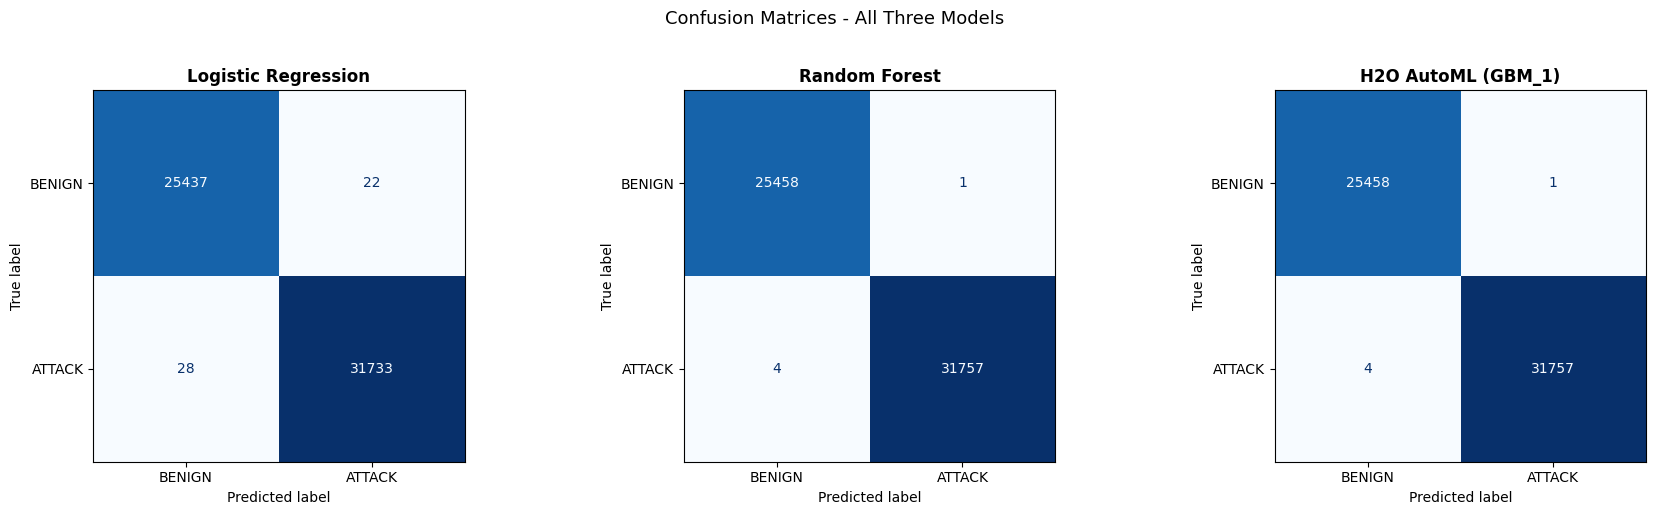

-----------------------------------------------------------------
 Saved as confusion_matrices_3models.png


In [19]:
# ── Confusion Matrices - All Three Models ──────────────────────────────

print("=" * 65)
print("  CONFUSION MATRICES - ALL THREE MODELS")
print("=" * 65)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Compute confusion matrices for each model
cm_lr  = confusion_matrix(y_test, y_pred_lr)
cm_rf  = confusion_matrix(y_test, y_pred_rf)
cm_aml = confusion_matrix(y_test, aml_pred)

print("  Models     : Logistic Regression | Random Forest | H2O AutoML (GBM)")
print("  Classes    : BENIGN (0) vs ATTACK (1)")
print("-" * 65)

# Plot all three confusion matrices side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
labels = ['BENIGN', 'ATTACK']
cms    = [cm_lr, cm_rf, cm_aml]
titles = ['Logistic Regression', 'Random Forest', 'H2O AutoML (GBM_1)']

for ax, cm, title in zip(axes, cms, titles):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(title, fontsize=12, fontweight='bold')

plt.suptitle('Confusion Matrices - All Three Models', fontsize=13, y=1.02)
plt.tight_layout()

# Save the figure
plt.savefig("confusion_matrices_3models.png", dpi=150, bbox_inches='tight')
plt.show()

print("-" * 65)
print(" Saved as confusion_matrices_3models.png")
print("=" * 65)



## Final Step: Shutdown H2O Cluster
Shutting down the H2O cluster to free up memory and Java resources.
Run this only after all H2O operations are fully complete.

In [20]:
# ── Shutdown H2O Cluster ──────────────────────────────────────────────

print("=" * 50)
print("  SHUTTING DOWN H2O CLUSTER")
print("=" * 50)
print("  All H2O data and models in memory will be lost.")
print("  Saved model files on disk are NOT affected.")
print("-" * 50)

# Shutdown H2O - frees Java process and memory
h2o.cluster().shutdown()

print("H2O cluster shut down successfully")
print("=" * 50)

  SHUTTING DOWN H2O CLUSTER
  All H2O data and models in memory will be lost.
  Saved model files on disk are NOT affected.
--------------------------------------------------
H2O session _sid_a9ba closed.
H2O cluster shut down successfully




The notebook demonstrated a full **Network Intrusion Detection System** pipeline:

| Stage | Details |
|---|---|
| Dataset | CICIDS2017 - Friday PortScan |
| Preprocessing | Label encoding, inf/NaN removal, 80/20 split, StandardScaler |
| Baseline Models | Logistic Regression, Random Forest |
| AutoML | TPOT, H2O AutoML |
| Explainability | SHAP Feature Importance |
| Best Model | H2O AutoML (GBM) |

Ishrath Basheer | P2836139